### Bank Customer Churn Prediction — ML & Deep Learning

### End-to-end binary classification project

Predicting whether a bank customer is likely to churn using exploratory data analysis, traditional machine learning, XGBoost.

## Objective

The target variable is `Exited`:

- `0` → Customer did not exit
- `1` → Customer exited

This is a **binary classification** problem.

### Workflow

1. Load and understand the data
2. Exploratory Data Analysis
3. Missing-value and class-imbalance analysis
4. Separate features and target
5. Train / validation / test split
6. Encoding and scaling
7. Compare ML models
8. Build a Neural Network
9. Tune XGBoost
10. Final held-out test evaluation
11. Generate Kaggle churn probabilities

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

RANDOM_STATE = 42

## 1. Load the data

For VS Code/local use, keep the files like:

```text
project/
├── bank_customer_churn_ML_DL_corrected.ipynb
└── data/
    ├── train.csv
    ├── test.csv
    └── sample_submission.csv
```

If running on Kaggle, replace the paths with the correct `/kaggle/input/...` paths.

In [2]:
import os
import pandas as pd

df_train = pd.read_csv(
    '/kaggle/input/competitions/playground-series-s4e1/train.csv'
)

df_test = pd.read_csv(
    '/kaggle/input/competitions/playground-series-s4e1/test.csv'
)

submission = pd.read_csv(
    '/kaggle/input/competitions/playground-series-s4e1/sample_submission.csv'
)
df = df_train.copy()

print("Training shape:", df_train.shape)
print("Test shape:", df_test.shape)

Training shape: (165034, 14)
Test shape: (110023, 13)


## 2. Basic data inspection

In [3]:
display(df.head())
print("\nData information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0



Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  object 
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  object 
 5   Gender           165034 non-null  object 
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 17.6+ MB

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
id,165034.0,8.251650e+04,47641.356500,0.00,41258.25,82516.5,1.237748e+05,165033.00
CustomerId,165034.0,1.569201e+07,71397.816791,15565701.00,15633141.00,15690169.0,1.575682e+07,15815690.00
CreditScore,165034.0,6.564544e+02,80.103340,350.00,597.00,659.0,7.100000e+02,850.00
Age,165034.0,3.812589e+01,8.867205,18.00,32.00,37.0,4.200000e+01,92.00
Tenure,165034.0,5.020353e+00,2.806159,0.00,3.00,5.0,7.000000e+00,10.00
Balance,165034.0,5.547809e+04,62817.663278,0.00,0.00,0.0,1.199395e+05,250898.09
NumOfProducts,165034.0,1.554455e+00,0.547154,1.00,1.00,2.0,2.000000e+00,4.00
HasCrCard,165034.0,7.539537e-01,0.430707,0.00,1.00,1.0,1.000000e+00,1.00
IsActiveMember,165034.0,4.977702e-01,0.499997,0.00,0.00,0.0,1.000000e+00,1.00
EstimatedSalary,165034.0,1.125748e+05,50292.865585,11.58,74637.57,117948.0,1.551525e+05,199992.48


## 3. Missing-value analysis

,Missing %
id,0.0
CustomerId,0.0
Surname,0.0
CreditScore,0.0
Geography,0.0
Gender,0.0
Age,0.0
Tenure,0.0
Balance,0.0
NumOfProducts,0.0


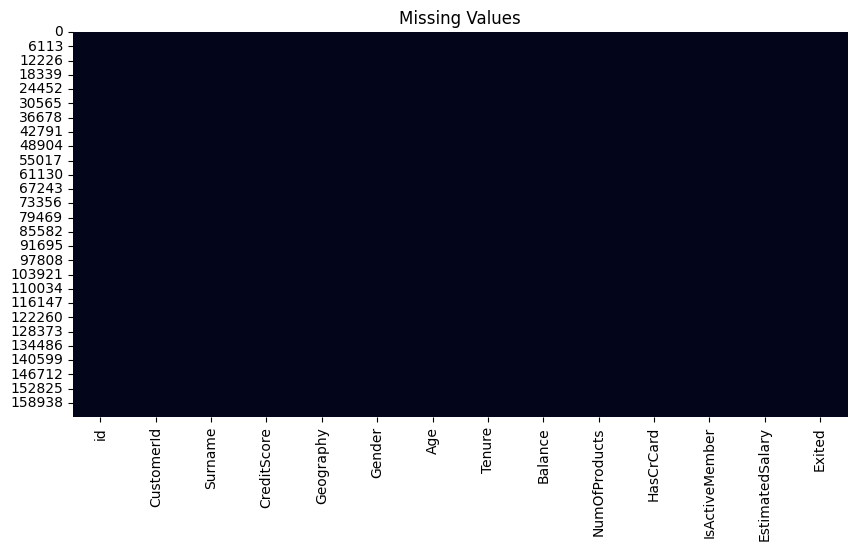

In [4]:
missing = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
display(missing.to_frame("Missing %"))

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

## 4. Target distribution

Exited
0    130113
1     34921
Name: count, dtype: int64

Target proportions:
Exited
0    0.788401
1    0.211599
Name: proportion, dtype: float64


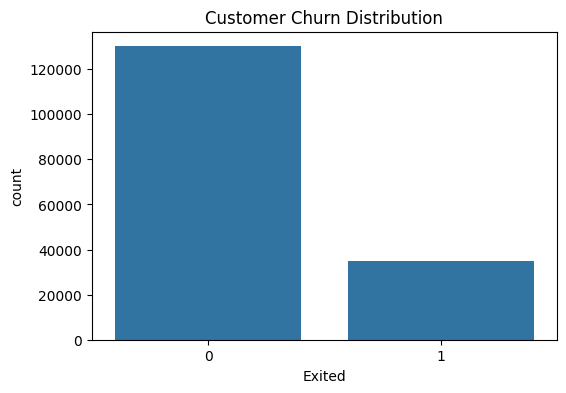

In [5]:
print(df["Exited"].value_counts())
print("\nTarget proportions:")
print(df["Exited"].value_counts(normalize=True))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Exited")
plt.title("Customer Churn Distribution")
plt.show()

## 5. Categorical feature analysis

In [6]:
cat_cols = [
    "Geography", "Gender", "Tenure", "NumOfProducts",
    "HasCrCard", "IsActiveMember", "Exited"
]

for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


Geography
Geography
France     94215
Spain      36213
Germany    34606
Name: count, dtype: int64

Gender
Gender
Male      93150
Female    71884
Name: count, dtype: int64

Tenure
Tenure
2     18045
7     17810
4     17554
8     17520
5     17268
1     16760
9     16709
3     16630
6     15822
10     5909
0      5007
Name: count, dtype: int64

NumOfProducts
NumOfProducts
2    84291
1    77374
3     2894
4      475
Name: count, dtype: int64

HasCrCard
HasCrCard
1.0    124428
0.0     40606
Name: count, dtype: int64

IsActiveMember
IsActiveMember
0.0    82885
1.0    82149
Name: count, dtype: int64

Exited
Exited
0    130113
1     34921
Name: count, dtype: int64


## 6. Numerical feature analysis

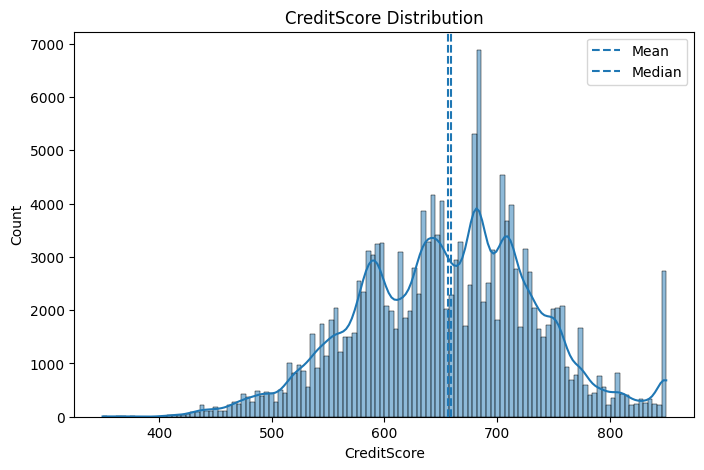

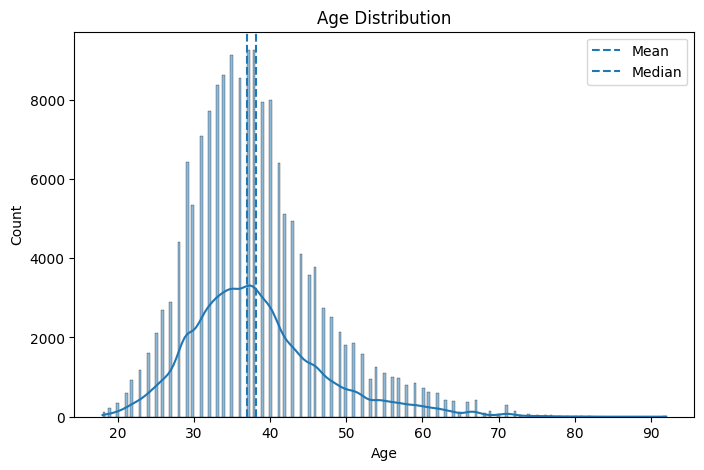

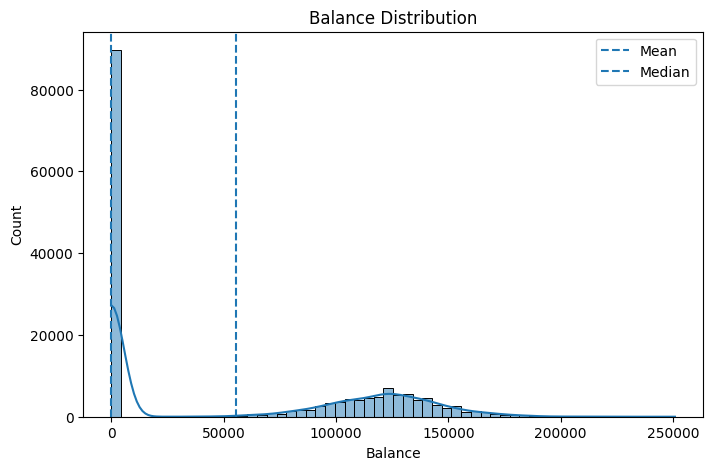

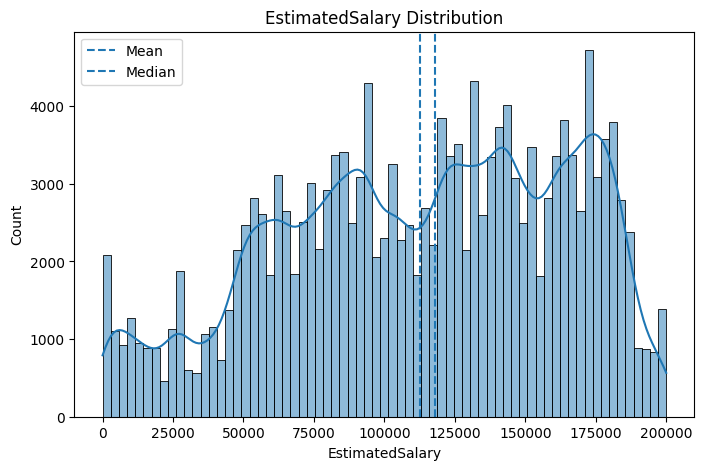

In [7]:
num_cols = ["CreditScore", "Age", "Balance", "EstimatedSalary"]

for col in num_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True)
    plt.axvline(df[col].mean(), linestyle="--", label="Mean")
    plt.axvline(df[col].median(), linestyle="--", label="Median")
    plt.title(f"{col} Distribution")
    plt.legend()
    plt.show()

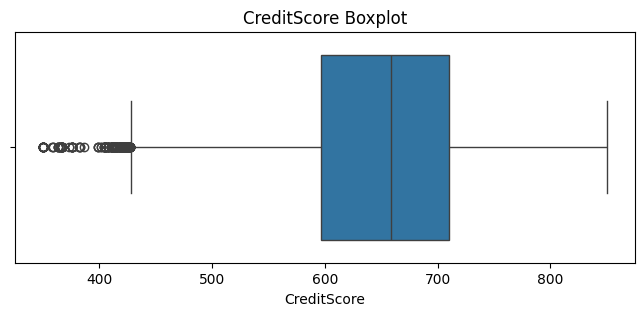

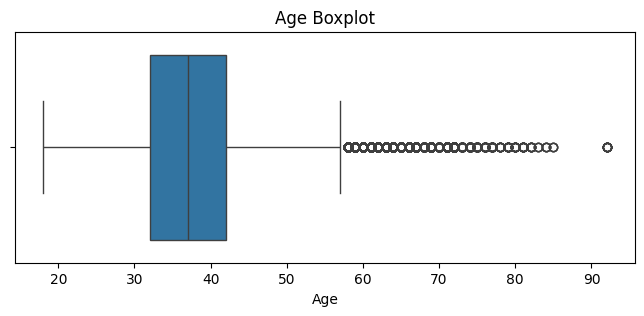

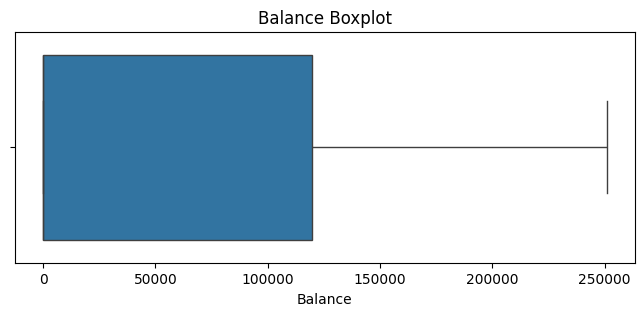

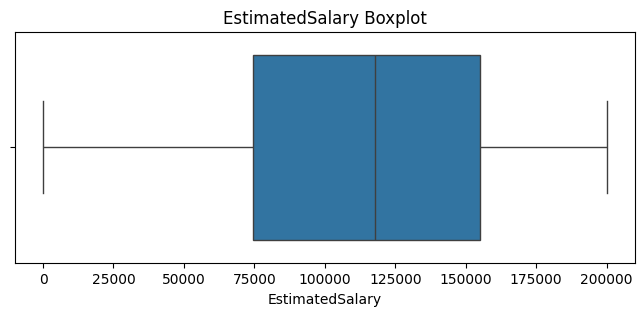

In [8]:
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"{col} Boxplot")
    plt.show()

## 7. Correlation analysis

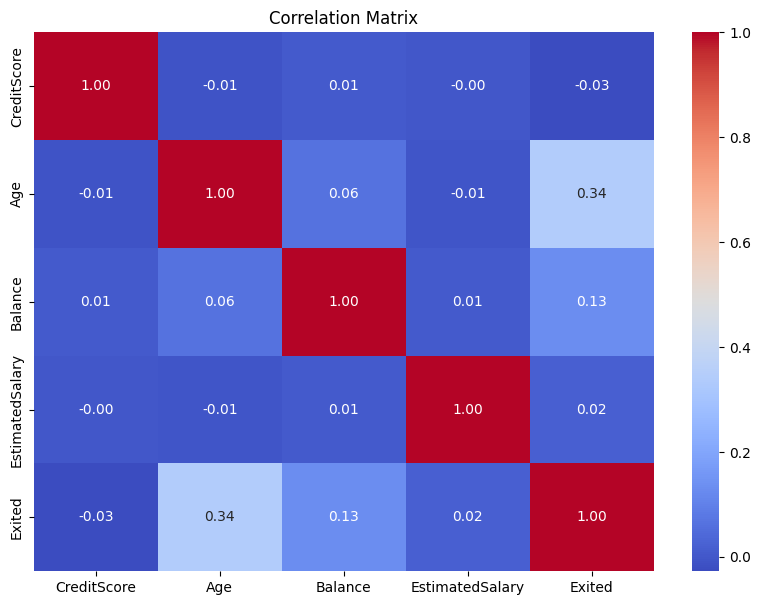

In [9]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[num_cols + ["Exited"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.show()

## 8. Define features and target

Identifier columns are excluded from the model.

- `X` = input features
- `y` = target

In [10]:
X = df.drop(["Exited", "id", "CustomerId", "Surname"], axis=1)
y = df["Exited"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (165034, 10)
y shape: (165034,)


## 9. Train / validation / test split

In [11]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (115523, 10)
Validation: (24755, 10)
Test: (24756, 10)


## 10. Preprocessing

Categorical features use `OneHotEncoder`; numerical features use `StandardScaler`.

The transformations are placed inside a `ColumnTransformer` and fitted through each model pipeline, which helps prevent preprocessing leakage.

In [12]:
categorical_features = ["Geography", "Gender"]

numerical_features = [
    "CreditScore", "Age", "Tenure", "Balance",
    "NumOfProducts", "HasCrCard", "IsActiveMember",
    "EstimatedSalary"
]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

## 11. Evaluation helper

In [13]:
def evaluate_model(model, X_val, y_val, model_name):
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob)
    }

## 12. Model comparison plan

We only look at three models here: **Logistic Regression**, **Decision Tree** and **XGBoost**.

For each model we do two runs:
1. **Baseline** - the model with simple default-ish settings, no tuning.
2. **Tuned** - `GridSearchCV` tries a few combinations of settings (hyperparameters) using cross-validation and keeps the best one, scored on ROC-AUC.

At the end we compare all 6 results (3 baseline + 3 tuned) in one table.

In [14]:
from sklearn.model_selection import GridSearchCV

baseline_results = []   # metrics for the 3 default models
tuned_results = []      # metrics for the 3 models after GridSearchCV
fitted_models = {}      # name -> fitted pipeline, used later for the test set

### 12a. Logistic Regression - baseline
Simple linear model. Fast, easy to explain, good sanity-check baseline.

In [15]:
lr_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

lr_baseline.fit(X_train, y_train)
baseline_results.append(evaluate_model(lr_baseline, X_val, y_val, "Logistic Regression (baseline)"))

print(classification_report(y_val, lr_baseline.predict(X_val)))

              precision    recall  f1-score   support

           0       0.85      0.96      0.90     19517
           1       0.70      0.38      0.50      5238

    accuracy                           0.84     24755
   macro avg       0.78      0.67      0.70     24755
weighted avg       0.82      0.84      0.82     24755



### 12b. Decision Tree - baseline
Splits the data on one feature at a time. Easy to visualise, but a single tree tends to overfit if it is left too deep - that's why `max_depth` is capped here.

In [16]:
dt_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE))
])

dt_baseline.fit(X_train, y_train)
baseline_results.append(evaluate_model(dt_baseline, X_val, y_val, "Decision Tree (baseline)"))

print(classification_report(y_val, dt_baseline.predict(X_val)))

              precision    recall  f1-score   support

           0       0.89      0.95      0.92     19517
           1       0.73      0.55      0.63      5238

    accuracy                           0.86     24755
   macro avg       0.81      0.75      0.77     24755
weighted avg       0.85      0.86      0.85     24755



### 12c. XGBoost - baseline
A boosted ensemble of many small trees, each one correcting the errors of the previous ones. Usually the strongest of the three out of the box.

In [17]:
xgb_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    ))
])

xgb_baseline.fit(X_train, y_train)
baseline_results.append(evaluate_model(xgb_baseline, X_val, y_val, "XGBoost (baseline)"))

print(classification_report(y_val, xgb_baseline.predict(X_val)))

              precision    recall  f1-score   support

           0       0.89      0.95      0.92     19517
           1       0.75      0.56      0.64      5238

    accuracy                           0.87     24755
   macro avg       0.82      0.75      0.78     24755
weighted avg       0.86      0.87      0.86     24755



## 13. Baseline comparison table

In [18]:
baseline_df = pd.DataFrame(baseline_results).sort_values("F1", ascending=False).reset_index(drop=True)
display(baseline_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost (baseline),0.867663,0.752315,0.558419,0.641026,0.889188
1,Decision Tree (baseline),0.861725,0.731919,0.546774,0.625943,0.880671
2,Logistic Regression (baseline),0.835185,0.701461,0.384880,0.497041,0.818628


## 14. Hyperparameter tuning

`GridSearchCV` fits the pipeline once per combination of settings (times `cv` folds), then keeps whichever combination scored best on ROC-AUC. This is slower than the baseline runs but it is a fair, automatic way to tune each model instead of guessing numbers by hand.

### 14a. Logistic Regression - tuning
Only one real knob to turn here: `C`, the inverse of regularisation strength (lower `C` = stronger regularisation = simpler model).

In [19]:
lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__penalty": ["l2"]
}

lr_grid = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    lr_param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1
)
lr_grid.fit(X_train, y_train)

print("Best params:", lr_grid.best_params_)

lr_tuned = lr_grid.best_estimator_
fitted_models["Logistic Regression (tuned)"] = lr_tuned
tuned_results.append(evaluate_model(lr_tuned, X_val, y_val, "Logistic Regression (tuned)"))

print(classification_report(y_val, lr_tuned.predict(X_val)))

Best params: {'model__C': 0.01, 'model__penalty': 'l2'}
              precision    recall  f1-score   support

           0       0.85      0.96      0.90     19517
           1       0.70      0.38      0.50      5238

    accuracy                           0.84     24755
   macro avg       0.78      0.67      0.70     24755
weighted avg       0.82      0.84      0.82     24755



### 14b. Decision Tree - tuning
Tuning `max_depth` controls how deep the tree can grow, and `min_samples_leaf` stops it from creating leaves with almost no data in them - both fight overfitting.

In [20]:
dt_param_grid = {
    "model__max_depth": [4, 6, 8, 10],
    "model__min_samples_leaf": [1, 5, 10, 20]
}

dt_grid = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    dt_param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print("Best params:", dt_grid.best_params_)

dt_tuned = dt_grid.best_estimator_
fitted_models["Decision Tree (tuned)"] = dt_tuned
tuned_results.append(evaluate_model(dt_tuned, X_val, y_val, "Decision Tree (tuned)"))

print(classification_report(y_val, dt_tuned.predict(X_val)))

Best params: {'model__max_depth': 8, 'model__min_samples_leaf': 20}
              precision    recall  f1-score   support

           0       0.89      0.95      0.92     19517
           1       0.74      0.55      0.63      5238

    accuracy                           0.86     24755
   macro avg       0.81      0.75      0.78     24755
weighted avg       0.86      0.86      0.86     24755



### 14c. XGBoost - tuning
More knobs than the other two models, so this grid takes the longest to run. `subsample` / `colsample_bytree` randomly hold back some rows/columns per tree, which usually helps generalisation.

In [21]:
xgb_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [4, 6],
    "model__learning_rate": [0.03, 0.1],
    "model__subsample": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss"))]),
    xgb_param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1
)
xgb_grid.fit(X_train, y_train)

print("Best params:", xgb_grid.best_params_)

xgb_tuned = xgb_grid.best_estimator_
fitted_models["XGBoost (tuned)"] = xgb_tuned
tuned_results.append(evaluate_model(xgb_tuned, X_val, y_val, "XGBoost (tuned)"))

print(classification_report(y_val, xgb_tuned.predict(X_val)))

Best params: {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 400, 'model__subsample': 0.8}
              precision    recall  f1-score   support

           0       0.89      0.95      0.92     19517
           1       0.75      0.55      0.64      5238

    accuracy                           0.87     24755
   macro avg       0.82      0.75      0.78     24755
weighted avg       0.86      0.87      0.86     24755



## 15. Baseline vs tuned - full comparison

In [22]:
fitted_models["Logistic Regression (baseline)"] = lr_baseline
fitted_models["Decision Tree (baseline)"] = dt_baseline
fitted_models["XGBoost (baseline)"] = xgb_baseline

tuned_df = pd.DataFrame(tuned_results)
all_results = pd.concat([baseline_df, tuned_df], ignore_index=True) \
    .sort_values("F1", ascending=False).reset_index(drop=True)

display(all_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost (baseline),0.867663,0.752315,0.558419,0.641026,0.889188
1,XGBoost (tuned),0.867340,0.753766,0.554028,0.638644,0.889993
2,Decision Tree (tuned),0.864149,0.738247,0.554601,0.633381,0.884282
3,Decision Tree (baseline),0.861725,0.731919,0.546774,0.625943,0.880671
4,Logistic Regression (baseline),0.835185,0.701461,0.384880,0.497041,0.818628
5,Logistic Regression (tuned),0.835387,0.704394,0.382589,0.495855,0.818712


## 16. Best model - final held-out test evaluation
The test set was never used for training or tuning, so this is the one honest check of how the winning model would perform on new data.

Best model on validation set: XGBoost (baseline)
              precision    recall  f1-score   support

           0       0.89      0.95      0.92     19518
           1       0.74      0.55      0.63      5238

    accuracy                           0.87     24756
   macro avg       0.82      0.75      0.78     24756
weighted avg       0.86      0.87      0.86     24756

Test ROC-AUC: 0.8867591887356621


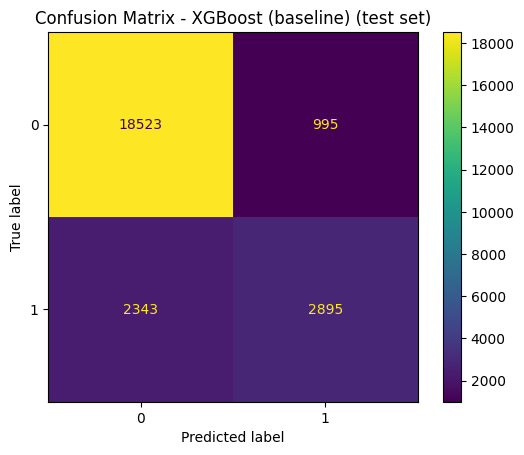

In [23]:
best_model_name = all_results.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print("Best model on validation set:", best_model_name)

best_test_pred = best_model.predict(X_test)
best_test_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, best_test_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, best_test_prob))

ConfusionMatrixDisplay.from_predictions(y_test, best_test_pred)
plt.title(f"Confusion Matrix - {best_model_name} (test set)")
plt.show()

## 17. Conclusion

This notebook trained Logistic Regression, Decision Tree and XGBoost twice each - once with default settings (baseline) and once tuned with `GridSearchCV` - and compared all six runs on the validation set. The table in section 15 shows how much (if at all) tuning helped each model, and section 16 confirms the winner's performance on the untouched test set.